# Train a Quantized MLPilot F1DS with Brevitas

In [ ]:
!pip install lightning

In [1]:
import os
import onnx
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image

import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import lightning as pl

from lightning.pytorch.loggers import TensorBoardLogger
from utils import split_csv
from utils_pytorch import AddGaussianNoise
from torchmetrics.image import TotalVariation

model_dir = os.environ['FINN_ROOT'] + "/notebooks/end2end_example/mlpilot/neuralpilot-main/"

**This is important -- always import onnx before torch**. This is a workaround for a [known bug](https://github.com/onnx/onnx/issues/2394).

In [2]:
from dataset import F1DS  # Import CustomDataset from dataset.py

In [3]:
# Define hyperparameters and data paths
hparams = {
    "learning_rate": 0.0005,
    "batch_size": 8,
    "num_workers": 8,
    "num_classes": 2,
    'max_epochs': 10,
    'dropout': 0.05,
    'latent_features': 256,
    'da': 1,
    'lda': 5e-3,
    'std_noise': 0.02
}

data_dir = './'
# csv_file = 'all_data_path.csv'
# split_csv('all_data_path.csv', 'train.csv', 'test.csv', split_ratio=0.8, seed=42)
csv_train = 'train.csv'
csv_test = 'test.csv'



# Define transformations for image (you can customize these as needed)
if hparams['da']:
    data_train_transform = transforms.Compose([
        transforms.Resize((16, 12)),  # Ajusta al tamaño correcto
        # transforms.Resize((224, 224)),  # Resize the image to the desired size
        transforms.ToTensor(),         # Convert to PyTorch tensor
        # transforms.Normalize(),
        AddGaussianNoise(0., hparams['std_noise']),         # add noise
        # transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4)
    ])
    data_test_transform = transforms.Compose([
        transforms.Resize((16, 12)),  # Ajusta al tamaño correcto
        transforms.ToTensor(),
    ])
else:
    data_train_transform = transforms.Compose([
        transforms.Resize((16, 12)),  # Ajusta al tamaño correcto
        transforms.ToTensor(),         # Convert to PyTorch tensor
    ])
    data_test_transform = transforms.Compose([
        transforms.Resize((16, 12)),  # Ajusta al tamaño correcto
        transforms.ToTensor(),
    ])

train_dataset = F1DS(csv_train, seq_len=1, transform=data_train_transform)
test_dataset = F1DS(csv_test, seq_len=1, transform=data_test_transform)

train_loader = DataLoader(train_dataset, batch_size=hparams['batch_size'], shuffle=True, num_workers=hparams['num_workers'], pin_memory=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=hparams['batch_size'], shuffle=False, num_workers=hparams['num_workers'], pin_memory=True)

In [4]:
count = 0
for x,y in train_loader:
    print("Input shape for 1 batch: " + str(x.shape))
    print("Label shape for 1 batch: " + str(y.shape))
    count += 1
    if count == 1:
        break

Input shape for 1 batch: torch.Size([8, 576])
Label shape for 1 batch: torch.Size([8, 2])


# Define the Quantized MLP Model <a id='define_quantized_mlp'></a>

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Target device: " + str(device))

Target device: cpu


In [6]:
# Define the QMLP model
from brevitas.nn import QuantLinear, QuantDropout, QuantReLU

class QMLPModel(nn.Module):
    def __init__(self, latent_features, dropout_rate=0.1, num_classes=2):
        super(QMLPModel, self).__init__()

        # self.flatten = nn.Flatten()
        self.fc1 = QuantLinear(3 * 16 * 12, 32, bias=True)
        self.fx = QuantLinear(32, latent_features, bias=True)

        self.dropout = QuantDropout(dropout_rate)
        self.predictor = nn.Sequential(
            QuantLinear(latent_features, num_classes, bias=True)
        )
        self.relu = QuantReLU()
    def forward(self, x, n_iter=1):
        b, f = x.size()

        # x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fx(x)
        x = self.relu(x)

        x = self.predictor(x)
        # x = x.view(b, s, -1)

        return x

model = QMLPModel(latent_features=hparams['latent_features'], dropout_rate=hparams['dropout'], num_classes=hparams['num_classes'])
model.to(device)

QMLPModel(
  (fc1): QuantLinear(
    in_features=576, out_features=32, bias=True
    (input_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
    )
    (output_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
    )
    (weight_quant): WeightQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
      (tensor_quant): RescalingIntQuant(
        (int_quant): IntQuant(
          (float_to_int_impl): RoundSte()
          (tensor_clamp_impl): TensorClampSte()
          (delay_wrapper): DelayWrapper(
            (delay_impl): _NoDelay()
          )
        )
        (scaling_impl): StatsFromParameterScaling(
          (parameter_list_stats): _ParameterListStats(
            (first_tracked_param): _ViewParameterWrapper(
              (view_shape_impl): OverTensorView()
            )
            (stats): _Stats(
              (stats_impl): AbsMax()
            )
          )
          (stats_scaling_impl): _StatsScaling(


In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=hparams['learning_rate'])

# Define Train and Test

In [8]:
def train(model, train_loader, optimizer):
    losses = []
    # ensure model is in training mode
    model.train()    
    
    for i, batch in enumerate(train_loader, 0):        
        images, targets = batch
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()   
                
        # forward pass
        predictions = model(images)
        # print(predictions)
        # tv_v = torch.diff(predictions[:,0],dim=-1).abs().sum(1).mean()
        # tik_w = torch.diff(predictions[:,1],dim=-1).square().sum(1).mean()

        # loss = nn.MSELoss()(predictions, targets) + self.lda * (tv_v + tik_w)
        loss = nn.L1Loss()(predictions, targets) #+ 5e-3 * (0.1*tv_v + tik_w)
        
        # backward pass + run optimizer to update weights
        loss.backward()
        optimizer.step()
        
        # keep track of loss value
        losses.append(loss.data.cpu().numpy()) 
           
    return np.mean(losses)

In [9]:
import torch

def test(model, test_loader):    
    # ensure model is in eval mode
    model.eval() 
    y_true = []
    y_pred = []
   
    with torch.no_grad():
        for batch in test_loader:
            images, targets = batch
            images = images.to(device)
            targets = targets.to(device)
            # inputs, target = inputs.to(device), target.to(device)
            # output_orig = model(inputs.float())
        predictions = model(images)
        # loss = nn.MSELoss()(predictions, targets)
        loss = nn.L1Loss()(predictions, targets)
        
    return loss

# Train the QNN <a id="train_qnn"></a>

We provide two options for training below: you can opt for training the model from scratch (slower) or use a pre-trained model (faster). The first option will give more insight into how the training process works, while the second option will likely give better accuracy.

In [10]:
def display_loss_plot(losses, title="Training loss", xlabel="Iterations", ylabel="Loss"):
    x_axis = [i for i in range(len(losses))]
    plt.plot(x_axis,losses)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

In [11]:
import numpy as np
from tqdm import tqdm, trange

# Setting seeds for reproducibility
torch.manual_seed(0)
np.random.seed(0)

running_loss = []
running_test = []
t = trange(hparams['max_epochs'], desc="Training loss", leave=True)

for epoch in t:
        loss_epoch = train(model, train_loader, optimizer)
        loss_test = test(model, test_loader)
        t.set_description("Training loss = %f test loss = %f" % (loss_epoch, loss_test))
        t.refresh() # to show immediately the update           
        running_loss.append(loss_epoch)
        running_test.append(loss_test)

Training loss:   0%|                                                                                                                                                                  | 0/10 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/_tensor.py:1255: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at ../c10/core/TensorImpl.h:1758.)
  return super(Tensor, self).rename(names)
Training loss = 0.084749 test loss = 0.022970: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:05<00:00,  1.77it/s]


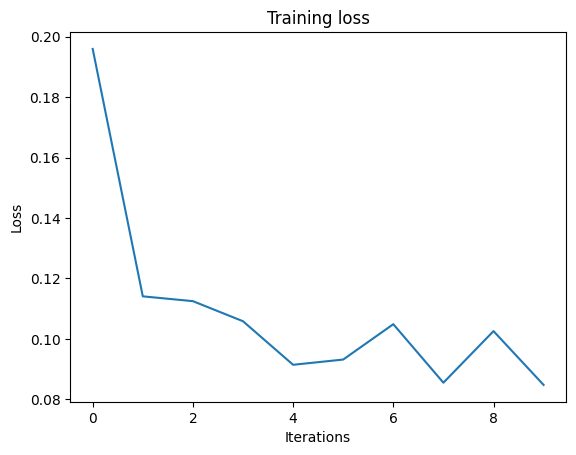

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt

loss_per_epoch = [np.mean(loss_per_epoch) for loss_per_epoch in running_loss]
display_loss_plot(loss_per_epoch)

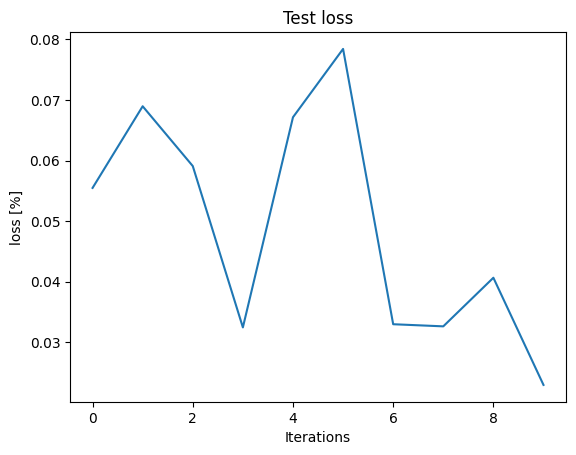

In [13]:
loss_per_epoch = [test_epoch.cpu().numpy() for test_epoch in running_test]
display_loss_plot(loss_per_epoch, title="Test loss", ylabel="loss [%]")

In [14]:
test(model, test_loader)

tensor(0.0348)

In [15]:
# Save the Brevitas model to disk
torch.save(model.state_dict(), "state_dict_self-trained_neuralpilot.pth")

## Load Pre-Trained Parameters <a id="load_pretrained"></a> (Los mismos entrenados con la mlp original, la que funcionaba).


In [16]:
import os
import torch

# Make sure the model is on CPU before loading a pretrained state_dict
model = model.cpu()

# Load pretrained weights
# trained_state_dict = torch.load(model_dir + "/state_dict_self-trained_neuralpilot.pth")#["models_state_dict"][0]

# model.load_state_dict(trained_state_dict, strict=False) 

trained_state_dict = torch.load("mlp_27k.ckpt", map_location=torch.device('cpu'))#["models_state_dict"][0]

state_dict = trained_state_dict['state_dict'].copy()

for name in trained_state_dict['state_dict']:
    state_dict[name[6:]] = trained_state_dict['state_dict'][name]
    del state_dict[name]

model.load_state_dict(state_dict, strict=False)

_IncompatibleKeys(missing_keys=['relu.act_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value'], unexpected_keys=[])

In [17]:
# Move the model back to it's target device
model.to(device)

# Test for accuracy
test(model, test_loader)

tensor(0.1711)

Next, we'll modify the expected input/output ranges. In FINN, we prefer to work with bipolar {-1, +1} instead of binary {0, 1} values. To achieve this, we'll create a "wrapper" model that handles the pre/postprocessing as follows:

* on the input side, we'll pre-process by (x + 1) / 2 in order to map incoming {-1, +1} inputs to {0, 1} ones which the trained network is used to. Since we're just multiplying/adding a scalar, these operations can be [*streamlined*](https://finn.readthedocs.io/en/latest/nw_prep.html#streamlining-transformations) by FINN and implemented with no extra cost.

* on the output side, we'll add a binary quantizer which maps everthing below 0 to -1 and everything above 0 to +1. This is essentially the same behavior as the sigmoid we used earlier, except the outputs are bipolar instead of binary.

In [29]:
from brevitas.nn import QuantIdentity


class MLPilotForExport(nn.Module):
    def __init__(self, my_pretrained_model):
        super(MLPilotForExport, self).__init__()
        self.pretrained = my_pretrained_model
        self.qnt_output = QuantIdentity(
            quant_type='FP', 
            scaling_impl_type='const',
            bit_width=None, min_val=-1.0, max_val=1.0)

# class MLPilotForExport(nn.Module):
#     def __init__(self, my_pretrained_model):
#         super(MLPilotForExport, self).__init__()
#         self.pretrained = my_pretrained_model
#         self.qnt_output = QuantIdentity(
#             quant_type='binary', 
#             scaling_impl_type='const',
#             bit_width=1, min_val=-1.0, max_val=1.0)
    
    def forward(self, x):
        # assume x contains bipolar {-1,1} elems
        # shift from {-1,1} -> {0,1} since that is the
        # input range for the trained network
        x = (x + torch.tensor([1.0]).to(x.device)) / 2.0  
        out_original = self.pretrained(x)
        out_final = self.qnt_output(out_original)   # output as {-1,1}     
        return out_final

model_for_export = MLPilotForExport(model)
model_for_export.to(device)



MLPilotForExport(
  (pretrained): QMLPModel(
    (fc1): QuantLinear(
      in_features=576, out_features=32, bias=True
      (input_quant): ActQuantProxyFromInjector(
        (_zero_hw_sentinel): StatelessBuffer()
      )
      (output_quant): ActQuantProxyFromInjector(
        (_zero_hw_sentinel): StatelessBuffer()
      )
      (weight_quant): WeightQuantProxyFromInjector(
        (_zero_hw_sentinel): StatelessBuffer()
        (tensor_quant): RescalingIntQuant(
          (int_quant): IntQuant(
            (float_to_int_impl): RoundSte()
            (tensor_clamp_impl): TensorClampSte()
            (delay_wrapper): DelayWrapper(
              (delay_impl): _NoDelay()
            )
          )
          (scaling_impl): StatsFromParameterScaling(
            (parameter_list_stats): _ParameterListStats(
              (first_tracked_param): _ViewParameterWrapper(
                (view_shape_impl): OverTensorView()
              )
              (stats): _Stats(
                (stats_impl)

In [32]:
 
# RNC: Verificar la cuantificación de la entrada y la salida
print(model_for_export.qnt_output)

QuantIdentity(
  (input_quant): ActQuantProxyFromInjector(
    (_zero_hw_sentinel): StatelessBuffer()
  )
  (act_quant): ActQuantProxyFromInjector(
    (_zero_hw_sentinel): StatelessBuffer()
  )
)


# Export to QONNX and Conversion to FINN-ONNX <a id="export_qonnx" ></a>


[ONNX](https://onnx.ai/) is an open format built to represent machine learning models, and the FINN compiler expects an ONNX model as input. We'll now export our network into ONNX to be imported and used in FINN for the next notebooks. Note that the particular ONNX representation used for FINN differs from standard ONNX, you can read more about this [here](https://finn.readthedocs.io/en/latest/internals.html#intermediate-representation-finn-onnx).

You can see below how we export a trained network in Brevitas into a FINN-compatible ONNX representation (QONNX). QONNX is the format we can export from Brevitas, to feed it into the FINN compiler, we will need to make a conversion to the FINN-ONNX format which is the intermediate representation the compiler works on. The conversion of the FINN-ONNX format is a FINN compiler transformation and to be able to apply it to our model, we will need to wrap it into [ModelWrapper](https://finn.readthedocs.io/en/latest/internals.html#modelwrapper). This is a wrapper around the ONNX model which provides several helper functions to make it easier to work with the model. Then we can call the conversion function to obtain the model in FINN-ONNX format.

In [34]:
from brevitas.export import export_qonnx
from qonnx.util.cleanup import cleanup as qonnx_cleanup
from qonnx.core.modelwrapper import ModelWrapper
from qonnx.core.datatype import DataType
from finn.transformation.qonnx.convert_qonnx_to_finn import ConvertQONNXtoFINN

ready_model_filename = "/neuralpilot-mlp-ready.onnx"
# input_shape = (1,1, 3, 12, 16)
input_shape = (1, 3*12* 16)

# create a QuantTensor instance to mark input as bipolar during export
# input_a = np.random.randint(0, 2, size=input_shape).astype(np.float32)
# input_a = 2 * input_a - 1
# scale = 1.0
# input_t = torch.from_numpy(input_a * scale)

input_t = torch.rand(input_shape)

#Move to CPU before export
model_for_export.cpu()

# Export to ONNX
export_qonnx(
    model_for_export, export_path=ready_model_filename, input_t=input_t
)

# clean-up
qonnx_cleanup(ready_model_filename, out_file=ready_model_filename)

# ModelWrapper
model = ModelWrapper(ready_model_filename)
# Setting the input datatype explicitly because it doesn't get derived from the export function
model.set_tensor_datatype(model.graph.input[0].name, DataType["FLOAT32"])

# # set tensor shape of third tensor in model tensor list
# tensor_shape = [1, 1, 28, 28]
# model.set_tensor_shape(tensor_list[2], tensor_shape)

model = model.transform(ConvertQONNXtoFINN())
model.save(ready_model_filename)

print("Model saved to %s" % ready_model_filename)

Model saved to /neuralpilot-mlp-ready.onnx


/opt/finn/deps/qonnx/src/qonnx/transformation/gemm_to_matmul.py:57: UserWarning: The GemmToMatMul transformation only offers explicit support for version 9 of the Gemm node, but the ONNX version of the supplied model is 14. Thus the transformation may fail or return incomplete results.
  warnings.warn(


In [35]:
model.graph

node {
  input: "global_in"
  input: "Add_0_param0"
  output: "Add_0_out0"
  name: "Add_0"
  op_type: "Add"
}
node {
  input: "Add_0_out0"
  input: "Div_0_param0"
  output: "Div_0_out0"
  name: "Div_0"
  op_type: "Div"
}
node {
  input: "Div_0_out0"
  input: "igHg1y"
  output: "E2ct3m"
  op_type: "MatMul"
}
node {
  input: "E2ct3m"
  input: "qPeFCO"
  output: "xnbQ5Z"
  op_type: "Mul"
}
node {
  input: "xnbQ5Z"
  input: "Gemm_0_param0"
  output: "Gemm_0_out0"
  op_type: "Add"
}
node {
  input: "Gemm_0_out0"
  input: "flG2VY"
  output: "rvfZPR"
  op_type: "MultiThreshold"
  attribute {
    name: "out_dtype"
    s: "UINT8"
    type: STRING
  }
  domain: "qonnx.custom_op.general"
}
node {
  input: "rvfZPR"
  input: "7cvMfp"
  output: "Quant_3_out0"
  op_type: "Mul"
}
node {
  input: "Quant_3_out0"
  input: "DRYMqw"
  output: "kefZu8"
  op_type: "MatMul"
}
node {
  input: "kefZu8"
  input: "k3hGGc"
  output: "93uc42"
  op_type: "Mul"
}
node {
  input: "93uc42"
  input: "Gemm_1_param0"
  ou

## View the Exported ONNX in Netron

Let's examine the exported ONNX model with [Netron](https://github.com/lutzroeder/netron), which is a visualizer for neural networks and allows interactive investigation of network properties. For example, you can click on the individual nodes and view the properties. Particular things of note:

* The input tensor "0" is annotated with `quantization: finn_datatype: BIPOLAR`
* The input preprocessing (x + 1) / 2 is exported as part of the network (initial `Add` and `Div` layers)
* Brevitas `QuantLinear` layers are exported to ONNX as `MatMul`. We've exported the padded version; shape of the first MatMul node's weight parameter is 600x64
* The weight parameters (second inputs) for MatMul nodes are annotated with `quantization: finn_datatype: INT2`
* The quantized activations are exported as `MultiThreshold` nodes with `domain=qonnx.custom_op.general`
* There's a final `MultiThreshold` node with threshold=0 to produce the final bipolar output (this is the `qnt_output` from `CybSecMLPForExport`

In [36]:
from finn.util.visualization import showInNetron

showInNetron(ready_model_filename)

Serving '/neuralpilot-mlp-ready.onnx' at http://0.0.0.0:8081


## 1. Launch a Build: Only Estimate Reports <a id="build_estimate_report"></a>

First, we'll launch a build that only generates the estimate reports, which does not require any synthesis. Note two things below: how the `generate_outputs` only contains `ESTIMATE_REPORTS`, but also how the `steps` uses a value of `estimate_only_dataflow_steps`. This skips steps like HLS synthesis to provide a quick estimate from analytical models.

In [40]:
import finn.builder.build_dataflow as build
import finn.builder.build_dataflow_config as build_cfg
import os
import shutil

model_dir = os.environ['FINN_ROOT'] + "/notebooks/end2end_example/mlpilot/neuralpilot-main"
model_file = "/neuralpilot-mlp-ready.onnx"

estimates_output_dir = "output_estimates_only"

#Delete previous run results if exist
if os.path.exists(estimates_output_dir):
    shutil.rmtree(estimates_output_dir)
    print("Previous run results deleted!")


cfg_estimates = build.DataflowBuildConfig(
    output_dir          = estimates_output_dir,
    mvau_wwidth_max     = 80,
    target_fps          = 1000000,
    synth_clk_period_ns = 10.0,
    fpga_part           = "xc7z020clg400-1",
    steps               = build_cfg.estimate_only_dataflow_steps,
    generate_outputs=[
        build_cfg.DataflowOutputType.ESTIMATE_REPORTS,
    ]
)

In [45]:
%%time
build.build_dataflow_cfg(model_file, cfg_estimates)

Building dataflow accelerator from /neuralpilot-mlp-ready.onnx
Intermediate outputs will be generated in /tmp/finn_dev_root
Final outputs will be generated in output_estimates_only
Build log is at output_estimates_only/build_dataflow.log
Running step: step_qonnx_to_finn [1/10]
Running step: step_tidy_up [2/10]
Running step: step_streamline [3/10]
Running step: step_convert_to_hw [4/10]
Running step: step_create_dataflow_partition [5/10]
Running step: step_specialize_layers [6/10]
Running step: step_target_fps_parallelization [7/10]
Running step: step_apply_folding_config [8/10]
Running step: step_minimize_bit_width [9/10]
Running step: step_generate_estimate_reports [10/10]
Completed successfully
CPU times: user 1.1 s, sys: 414 ms, total: 1.52 s
Wall time: 893 ms


0

In [46]:
! cat {estimates_output_dir}/report/estimate_network_performance.json

{
  "critical_path_cycles": 128,
  "max_cycles": 64,
  "max_cycles_node_name": "MVAU_hls_0",
  "estimated_throughput_fps": 1562500.0,
  "estimated_latency_ns": 1280.0
}

In [47]:
import json
def read_json_dict(filename):
    with open(filename, "r") as f:
        ret = json.load(f)
    return ret
read_json_dict(estimates_output_dir + "/report/estimate_layer_cycles.json")

{'MVAU_hls_0': 64, 'MVAU_rtl_0': 64}

In [48]:
read_json_dict(estimates_output_dir + "/report/estimate_layer_resources.json")

{'MVAU_hls_0': {'BRAM_18K': 29,
  'BRAM_efficiency': 0.12260536398467432,
  'LUT': 16104,
  'URAM': 0,
  'URAM_efficiency': 1,
  'DSP': 0},
 'MVAU_rtl_0': {'BRAM_18K': 2,
  'BRAM_efficiency': 0.1111111111111111,
  'LUT': 0,
  'URAM': 0,
  'URAM_efficiency': 1,
  'DSP': 8},
 'total': {'BRAM_18K': 31.0, 'LUT': 16104.0, 'URAM': 0.0, 'DSP': 8.0}}

## 2. Launch a Build: Stitched IP, out-of-context synth and rtlsim Performance <a id="build_ip_synth_rtlsim"></a>

Once we have a configuration that gives satisfactory estimates, we can move on to generating the accelerator. We can do this in different ways depending on how we want to integrate the accelerator into a larger system. For instance, if we have a larger streaming system built in Vivado or if we'd like to re-use this generated accelerator as an IP component in other projects, the `STITCHED_IP` output product is a good choice. We can also use the `OOC_SYNTH` output product to get post-synthesis resource and clock frequency numbers for our accelerator.

<font color="red">**Live FINN tutorial:** These next builds will take about 10 minutes to complete since multiple calls to Vivado and a call to RTL simulation are involved. While this is running, you can examine the generated files with noVNC -- it is running on **(your AWS URL):6080/vnc.html**

* Once the `step_hls_codegen [8/16]` below is completed, you can view the generated HLS code under its own folder for each layer: `/tmp/finn_dev_ubuntu/code_gen_ipgen_MVAU_hls_XXXXXX`
    
* Once the `step_create_stitched_ip [11/16]` below is completed, you can view the generated stitched IP in Vivado under `/home/ubuntu/finn/notebooks/end2end_example/cybersecurity/output_ipstitch_ooc_rtlsim/stitched_ip`
</font> 

In [54]:
import finn.builder.build_dataflow as build
import finn.builder.build_dataflow_config as build_cfg
import os
import shutil

model_dir = os.environ['FINN_ROOT'] + "/notebooks/end2end_example/mlpilot/neuralpilot-main"
model_file = "/neuralpilot-mlp-ready.onnx"

rtlsim_output_dir = "output_ipstitch_ooc_rtlsim"

#Delete previous run results if exist
if os.path.exists(rtlsim_output_dir):
    shutil.rmtree(rtlsim_output_dir)
    print("Previous run results deleted!")

cfg_stitched_ip = build.DataflowBuildConfig(
    output_dir          = rtlsim_output_dir,
    mvau_wwidth_max     = 80,
    target_fps          = 10000, #1000000,
    synth_clk_period_ns = 10.0,
    fpga_part           = "xc7z020clg400-1",
    generate_outputs=[
        build_cfg.DataflowOutputType.STITCHED_IP,
        build_cfg.DataflowOutputType.RTLSIM_PERFORMANCE,
        build_cfg.DataflowOutputType.OOC_SYNTH,
    ]
)

In [55]:
!export FINN_XILINX_PATH=/opt/Xilinx
!export FINN_XILINX_VERSION=2022.2

In [56]:
%%time
build.build_dataflow_cfg(model_file, cfg_stitched_ip)

Building dataflow accelerator from /neuralpilot-mlp-ready.onnx
Intermediate outputs will be generated in /tmp/finn_dev_root
Final outputs will be generated in output_ipstitch_ooc_rtlsim
Build log is at output_ipstitch_ooc_rtlsim/build_dataflow.log
Running step: step_qonnx_to_finn [1/19]
Running step: step_tidy_up [2/19]
Running step: step_streamline [3/19]
Running step: step_convert_to_hw [4/19]
Running step: step_create_dataflow_partition [5/19]
Running step: step_specialize_layers [6/19]
Running step: step_target_fps_parallelization [7/19]
Running step: step_apply_folding_config [8/19]
Running step: step_minimize_bit_width [9/19]
Running step: step_generate_estimate_reports [10/19]
Running step: step_hw_codegen [11/19]
Running step: step_hw_ipgen [12/19]
Running step: step_set_fifo_depths [13/19]
Running step: step_create_stitched_ip [14/19]
Running step: step_measure_rtlsim_performance [15/19]
Running step: step_out_of_context_synthesis [16/19]
Running step: step_synthesize_bitfile 

0

In [57]:
! cat {rtlsim_output_dir}/report/ooc_synth_and_timing.json

{
  "vivado_proj_folder": "/tmp/finn_dev_root/synth_out_of_context_9ssrl9h2/results_finn_design_wrapper",
  "LUT": 3433.0,
  "LUTRAM": 8.0,
  "FF": 3190.0,
  "DSP": 0.0,
  "BRAM": 130.0,
  "BRAM_18K": 257.0,
  "BRAM_36K": 2.0,
  "URAM": 0.0,
  "Carry": 800.0,
  "WNS": 0.287,
  "Delay": 0.287,
  "vivado_version": 2022.2,
  "vivado_build_no": 3671981.0,
  "": 0,
  "fmax_mhz": 102.95480284155256,
  "estimated_throughput_fps": 12567.72495624421
}

In [58]:
! cat {rtlsim_output_dir}/report/rtlsim_performance.json

{
  "N_IN_TXNS": 32,
  "N_OUT_TXNS": 2,
  "cycles": 8469,
  "N": 1,
  "latency_cycles": 8469,
  "runtime[ms]": 0.08469,
  "throughput[images/s]": 11807.769512339119,
  "fclk[mhz]": 100.0,
  "stable_throughput[images/s]": 11807.769512339119
}

## 3. (Optional) Launch a Build: PYNQ Bitfile and Driver <a id="build_bitfile_driver"></a>

<font color="red">**Live FINN tutorial:** This section is not included in the hands-on tutorial due to the bitfile synthesis time (15-20 min). If you own a PYNQ board, we encourage you to uncomment the cells below to try it out on your own after the tutorial.</font>

In [60]:
import finn.builder.build_dataflow as build
import finn.builder.build_dataflow_config as build_cfg
import os
import shutil

model_dir = os.environ['FINN_ROOT'] + "/notebooks/end2end_example/mlpilot/neuralpilot-main"
model_file = "/neuralpilot-mlp-ready.onnx"

final_output_dir = "output_final"

#Delete previous run results if exist
if os.path.exists(final_output_dir):
    shutil.rmtree(final_output_dir)
    print("Previous run results deleted!")

cfg = build.DataflowBuildConfig(
    output_dir          = final_output_dir,
    mvau_wwidth_max     = 80,
    target_fps          = 10000, #1000000
    synth_clk_period_ns = 10.0,
    board               = "Pynq-Z1",
    shell_flow_type     = build_cfg.ShellFlowType.VIVADO_ZYNQ,
    generate_outputs=[
        build_cfg.DataflowOutputType.BITFILE,
        build_cfg.DataflowOutputType.PYNQ_DRIVER,
        build_cfg.DataflowOutputType.DEPLOYMENT_PACKAGE,
    ]
)

In [ ]:
%%time
build.build_dataflow_cfg(model_file, cfg)

Building dataflow accelerator from /neuralpilot-mlp-ready.onnx
Intermediate outputs will be generated in /tmp/finn_dev_root
Final outputs will be generated in output_final
Build log is at output_final/build_dataflow.log
Running step: step_qonnx_to_finn [1/19]
Running step: step_tidy_up [2/19]
Running step: step_streamline [3/19]
Running step: step_convert_to_hw [4/19]
Running step: step_create_dataflow_partition [5/19]
Running step: step_specialize_layers [6/19]
Running step: step_target_fps_parallelization [7/19]
Running step: step_apply_folding_config [8/19]
Running step: step_minimize_bit_width [9/19]
Running step: step_generate_estimate_reports [10/19]
Running step: step_hw_codegen [11/19]
Running step: step_hw_ipgen [12/19]
Running step: step_set_fifo_depths [13/19]
Running step: step_create_stitched_ip [14/19]
Running step: step_measure_rtlsim_performance [15/19]
Running step: step_out_of_context_synthesis [16/19]
Running step: step_synthesize_bitfile [17/19]


ERROR: [Board 49-71] The board_part definition was not found for www.digilentinc.com:pynq-z1:part0:1.0. The project's board_part property was not set, but the project's part property was set to xc7z020clg400-1. Valid board_part values can be retrieved with the 'get_board_parts' Tcl command. Check if board.repoPaths parameter is set and the board_part is installed from the tcl app store.
Traceback (most recent call last):
  File "/opt/finn/src/finn/builder/build_dataflow.py", line 158, in build_dataflow_cfg
    model = transform_step(model, cfg)
  File "/opt/finn/src/finn/builder/build_dataflow_steps.py", line 790, in step_synthesize_bitfile
    model = model.transform(
  File "/opt/finn/deps/qonnx/src/qonnx/core/modelwrapper.py", line 140, in transform
    (transformed_model, model_was_changed) = transformation.apply(transformed_model)
  File "/opt/finn/src/finn/transformation/fpgadataflow/make_zynq_proj.py", line 352, in apply
    model = model.transform(MakeZYNQProject(self.platform,

> /opt/finn/src/finn/transformation/fpgadataflow/make_zynq_proj.py(269)apply()
    267         bitfile_name = vivado_pynq_proj_dir + "/finn_zynq_link.runs/impl_1/top_wrapper.bit"
    268         if not os.path.isfile(bitfile_name):
--> 269             raise Exception(
    270                 "Synthesis failed, no bitfile found. Check logs under %s" % vivado_pynq_proj_dir
    271             )



For our final build, the output products include the bitfile (and the accompanying .hwh file, also needed to execute correctly on PYNQ for Zynq platforms):

In [ ]:
! ls {final_output_dir}/bitfile